# WG6 Roman variable-star light curves: scoping (T28)
Regenerates every README figure from `data/` (no drive needed). Heavy work is in `tools/extract_wg6.py`, `tools/fetch_ogle_truth.py`, `tools/audit/wg6_{inventory,truth,profile,examples}.py`.

In [1]:
import sys, numpy as np, pandas as pd
from pathlib import Path
HERE = Path.cwd() if (Path.cwd()/'figlib.py').exists() else Path('reports/2026-11-12_wg6-dataset-scoping')
sys.path.insert(0, str(HERE))
import importlib, figlib; importlib.reload(figlib)
from figlib import *
inv = load_inventory(); b, s = load_profile()
truth = pd.read_csv(DATA/'truth_joined.csv.gz'); truth['cls']=truth['cls'].astype(str)
pc = pd.read_csv(DATA/'period_check.csv')
print(len(inv), 'stars;', len(s), 'profiled')

68824 stars; 524 profiled


## Counts per class (every file counted from its header)

         stars  median_points_all_bands  with_period  period_rate
cls                                                              
ROT       3172                  12379.0         3172     1.000000
FLARE      390                 211180.5          273     0.700000
ECL      47668                   7401.0        47660     0.999832
ELL       4227                   7351.0         4227     1.000000
HB          94                  12703.5           94     1.000000
RRLYR     6809                   6719.0         6809     1.000000
DSCT      1160                  11314.0         1149     0.990517
CEP         25                   1898.0           25     1.000000
T2CEP      224                   8374.5          224     1.000000
LPV       4373                   1906.0         4373     1.000000
VVV-LPV    401                     50.0            0     0.000000
BLAP         9                  14024.0            0     0.000000
DN         198                   5876.5            0     0.000000
TR        

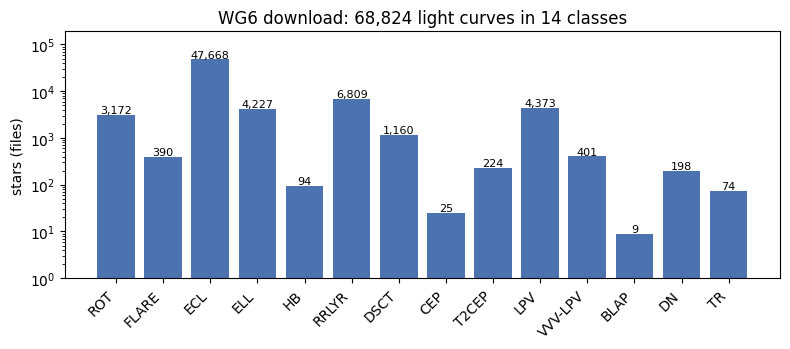

In [2]:
t = inv.groupby('cls').agg(stars=('NAME','size'), median_points_all_bands=('n_total','median')).reindex(ORDER).dropna()
rates = pd.read_csv(DATA/'truth_match_rates.csv', index_col=0)
t = t.join(rates[['with_period','period_rate']]); print(t.to_string()); print('total', int(t.stars.sum()))
fig_counts(inv);

## Per-class profile (primary band: OGLE I; TESS sector for flares), sample medians

In [3]:
I = b[(b.band=='LC_I') | ((b.cls=='FLARE') & (b.band=='0'))]
prof = I.groupby('cls')[['n','span_d','med_dt_min','n_seasons','med_season_len_d','med_season_n','med_y','p2p','med_err']].median()
pt = truth.groupby('cls').P_true.describe(percentiles=[.05,.5,.95])[['count','5%','50%','95%']]
prof = prof.join(pt).reindex(ORDER).dropna(how='all'); prof.round(3).to_csv(DATA/'profile_table.csv'); prof.round(3)

,n,span_d,med_dt_min,n_seasons,med_season_len_d,med_season_n,med_y,p2p,med_err,count,5%,50%,95%
cls,,,,,,,,,,,,,
ROT,12014.0,5106.988,59.411,14.0,266.630,781.75,16.653,0.013,0.010,3172.0,1.021,25.667,74.640
FLARE,89023.0,24.278,0.333,1.0,24.278,89023.00,11.145,0.005,0.005,273.0,0.323,1.400,124.088
ECL,7113.0,2071.635,56.894,6.0,270.627,898.00,18.084,0.060,0.027,47660.0,0.311,0.577,8.222
ELL,10528.5,2071.647,21.931,6.0,270.638,2222.75,16.506,0.016,0.008,4227.0,0.363,1.394,227.356
HB,12313.5,6661.863,36.277,22.0,252.415,255.00,13.772,0.003,0.009,94.0,128.073,245.519,437.140
RRLYR,6516.0,2714.771,67.295,8.0,268.638,824.00,17.600,0.059,0.016,6809.0,0.267,0.509,0.684
DSCT,14309.0,3526.649,23.918,10.0,268.638,1220.00,17.441,0.064,0.016,1149.0,0.049,0.075,0.151
CEP,1774.0,5065.011,1290.614,14.0,242.643,74.50,16.931,0.058,0.011,25.0,0.294,1.107,4.449
T2CEP,2121.0,4975.497,1117.660,14.0,242.643,79.00,16.483,0.032,0.008,224.0,1.249,8.520,36.660


## Truth periods per class vs the SMARTS range
Filled: catalog periods for every star; hatched: our top LS peak on the sample (only meaningful for classes without a catalog).

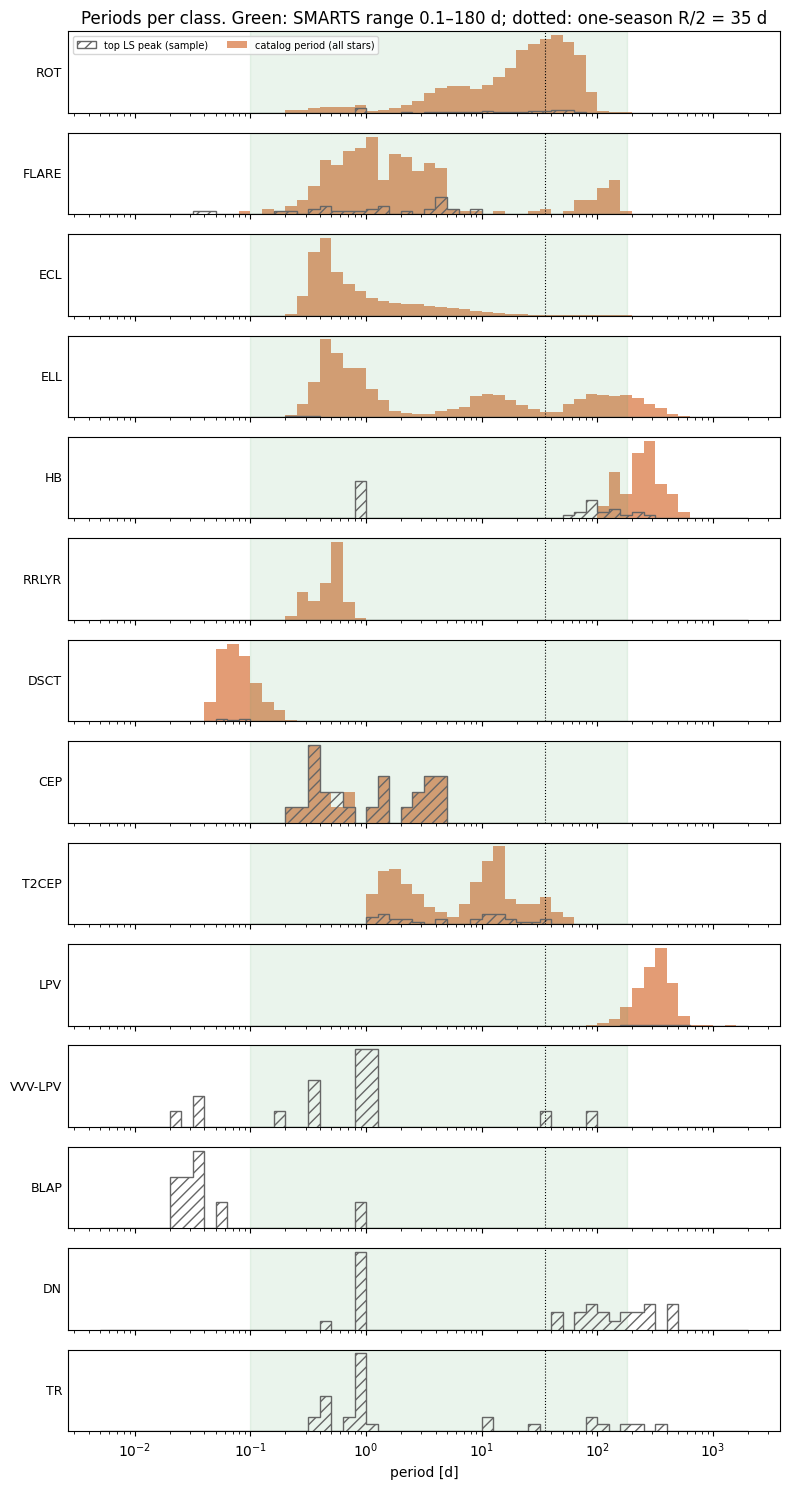

In [4]:
fig_periods(s, truth);

In [5]:
for c, g in truth.groupby('cls'):
    p = g.P_true.dropna()
    if len(p): print(f"{c:8s} n={len(p):6d}  frac 0.1-35 d: {((p>0.1)&(p<35)).mean():.2f}  frac 1-35 d: {((p>1)&(p<35)).mean():.2f}")

CEP      n=    25  frac 0.1-35 d: 1.00  frac 1-35 d: 0.52
DSCT     n=  1149  frac 0.1-35 d: 0.23  frac 1-35 d: 0.00
ECL      n= 47660  frac 0.1-35 d: 0.99  frac 1-35 d: 0.31
ELL      n=  4227  frac 0.1-35 d: 0.74  frac 1-35 d: 0.30
FLARE    n=   273  frac 0.1-35 d: 0.87  frac 1-35 d: 0.50
HB       n=    94  frac 0.1-35 d: 0.00  frac 1-35 d: 0.00
LPV      n=  4373  frac 0.1-35 d: 0.00  frac 1-35 d: 0.00
ROT      n=  3172  frac 0.1-35 d: 0.63  frac 1-35 d: 0.58
RRLYR    n=  6809  frac 0.1-35 d: 1.00  frac 1-35 d: 0.00
T2CEP    n=   224  frac 0.1-35 d: 0.94  frac 1-35 d: 0.94


## Noise vs magnitude
Point-to-point scatter (robust MAD of first differences / sqrt 2). For fast variables (DSCT, RRLYR, ECL) it includes real variability between consecutive points. Green band: SMARTS-TESS 30-min p2p over 100 dev files.

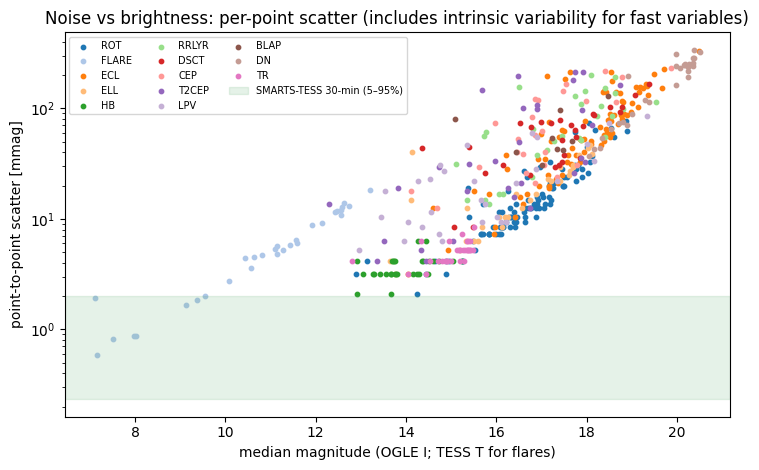

In [6]:
fig_noise(b);

## Example light curves and periodograms, one star per class

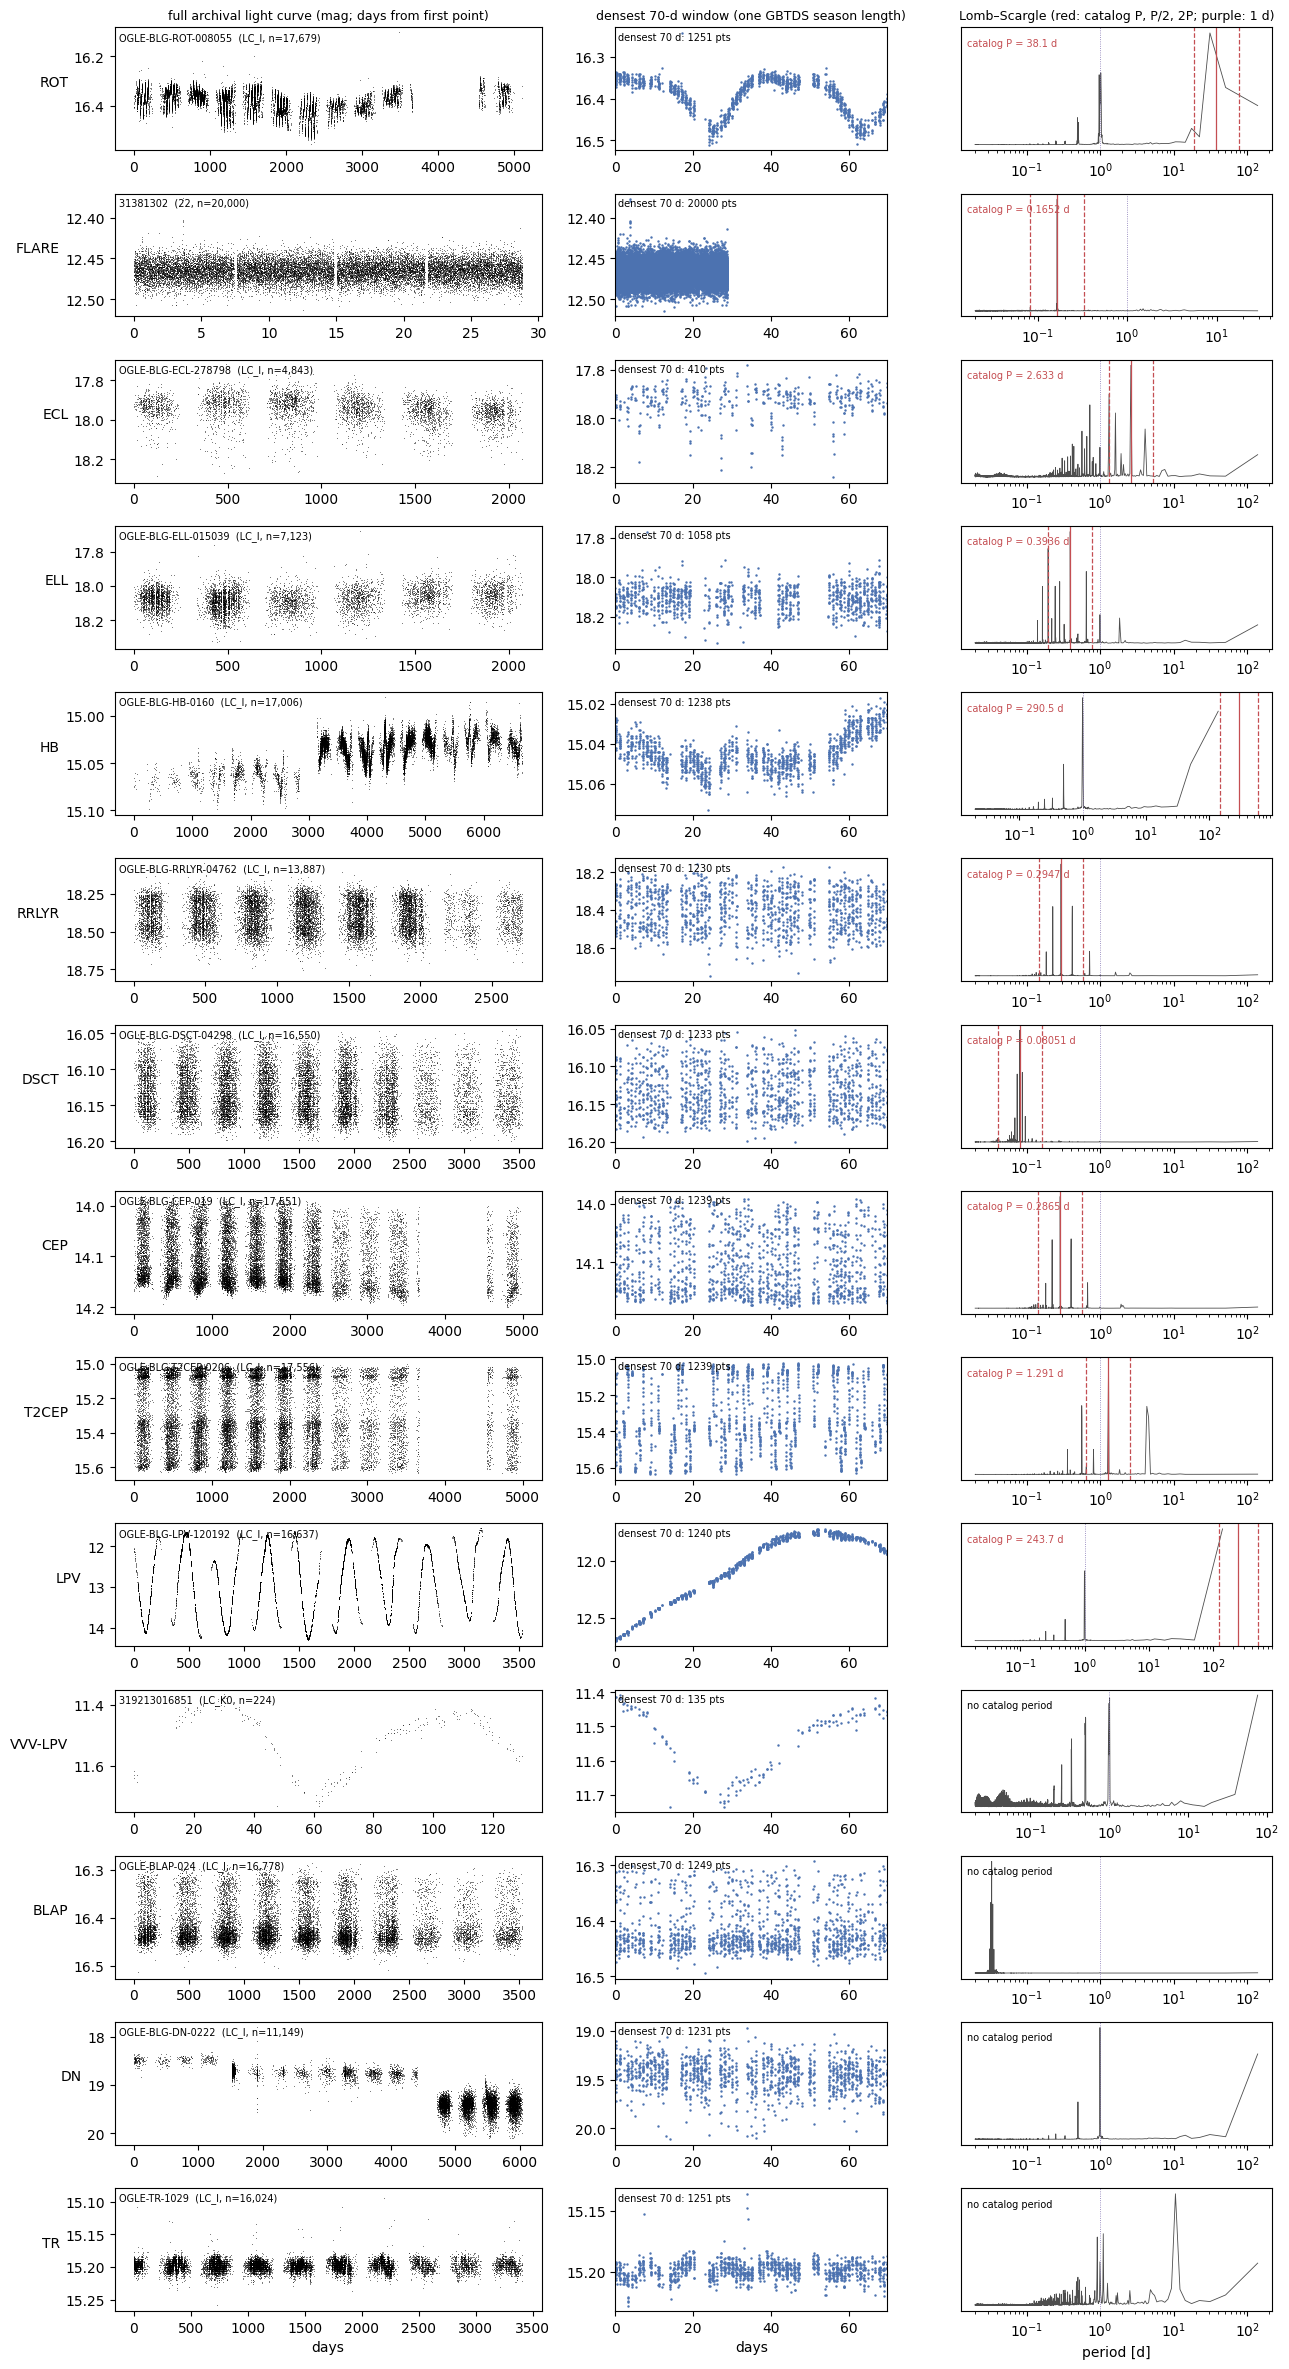

In [7]:
fig_examples();

## Time coverage for one star (ROT example) vs a GBTDS-like season

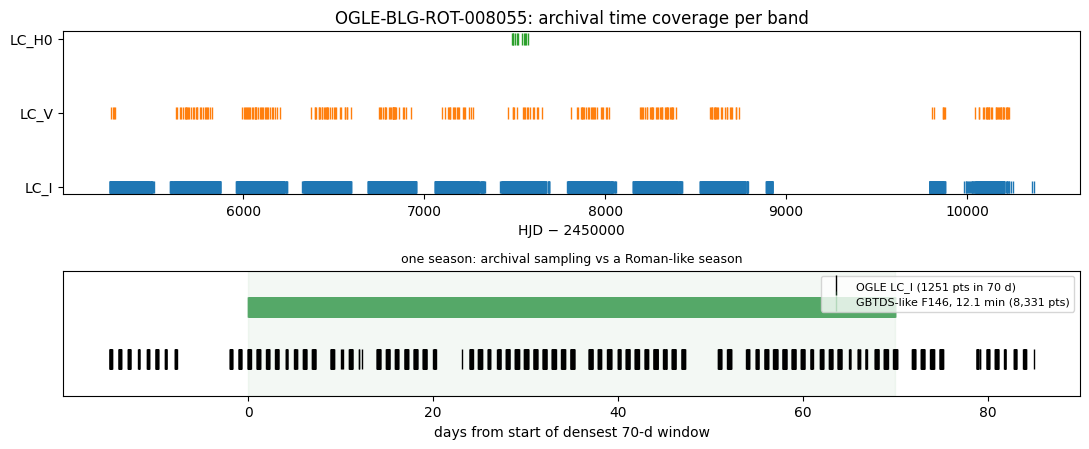

In [8]:
fig_coverage('ROT');

## Stored vs measured period
Our measured period = top Lomb–Scargle peak after skipping peaks at 0.95–1.05 d, 0.49–0.51 d and >300 d (ground-based daily/yearly window peaks), except LPV (periods >300 d are real) where the raw top peak is used.

outcome,2P,P/2,match,no measurement,other
cls,,,,,
BLAP,0,0,0,9,0
CEP,0,0,23,0,2
DN,0,0,0,30,0
DSCT,0,0,28,2,0
ECL,0,79,1,2,8
ELL,0,28,1,0,1
FLARE,1,1,14,8,6
HB,0,16,1,9,4
LPV,0,0,30,0,0


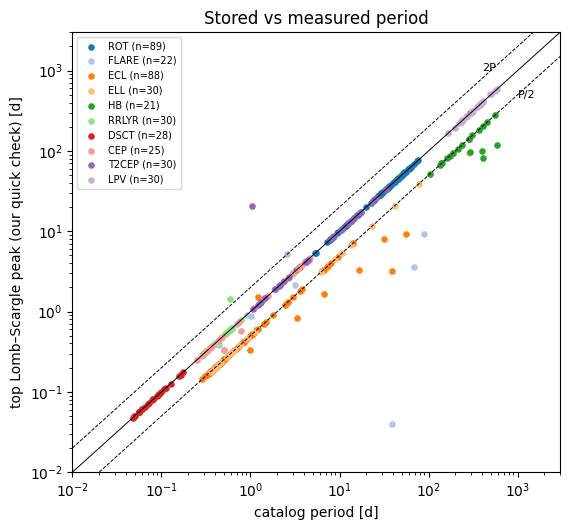

In [9]:
pc['P1_raw'] = pc['P1']
pc['P1'] = np.where(pc.cls.isin(['LPV']), pc.P1_raw, pc.P1c)
fig_period_check(pc)
def oc(r):
    if not (np.isfinite(r.P_true) and np.isfinite(r.P1)): return 'no measurement'
    x = r.P1/r.P_true
    for k,n in ((1,'match'),(0.5,'P/2'),(2,'2P')):
        if abs(x/k-1) < 0.1: return n
    return 'other'
pc['outcome'] = pc.apply(oc, axis=1)
tab = pd.crosstab(pc.cls, pc.outcome); tab.to_csv(DATA/'period_check_table.csv'); tab

## Pipeline timing (3 ROT stars, i5, one process)

In [10]:
tm = pd.read_csv(DATA/'pipeline_timing.csv'); print(tm[['NAME','P_true','input','fill_frac','n_acf_lags','seconds','P_found']].round(3).to_string())
sec = tm[tm.input.str.startswith('synthetic')].seconds.mean()
print(f'mean {sec:.2f} s/star -> all {len(inv):,} WG6 stars, one season each: {sec*len(inv)/3600:.1f} CPU-h; ROT only ({(inv.cls=="ROT").sum()}): {sec*(inv.cls=="ROT").sum()/60:.0f} CPU-min')

                  NAME  P_true                                    input  fill_frac  n_acf_lags  seconds  P_found
0  OGLE-BLG-ROT-006608   2.074         OGLE densest 70 d on 15-min grid      0.154          17    0.021      NaN
1  OGLE-BLG-ROT-006608   2.074         OGLE densest 70 d on 60-min grid      0.255        1176    0.012      NaN
2  OGLE-BLG-ROT-006608   2.074  synthetic 70 d at 12.1 min (Roman-like)      1.000        5831    0.834    2.074
3  OGLE-BLG-ROT-007851  16.012         OGLE densest 70 d on 15-min grid      0.183          19    0.018      NaN
4  OGLE-BLG-ROT-007851  16.012         OGLE densest 70 d on 60-min grid      0.304        1149    0.009      NaN
5  OGLE-BLG-ROT-007851  16.012  synthetic 70 d at 12.1 min (Roman-like)      1.000        5831    0.689   16.128
6  OGLE-BLG-ROT-007013  14.610         OGLE densest 70 d on 15-min grid      0.154          17    0.019      NaN
7  OGLE-BLG-ROT-007013  14.610         OGLE densest 70 d on 60-min grid      0.255        1176  

# Part 2: the resampled (Roman-cadence) set
Inputs are in `data/resampled/` (from `tools/audit/wg6r_profile.py`, `wg6_truth.py --resampled`, `wg6r_pipeline.py` and `wg6r_examples.py`). Nothing here needs the drive.

In [11]:
importlib.reload(figlib); from figlib import *
rinv = pd.read_csv(RD/'inventory.csv.gz', low_memory=False)
print(rinv.groupby(['cls','variant']).agg(files=('member','size'), objects=('star_id','nunique')).unstack('variant').fillna(0).astype(int).to_string())
rtr = pd.read_csv(RD/'truth.csv.gz', low_memory=False)
print(rtr.groupby('cls').agg(stars=('star_id','size'), with_P=('P_true', lambda x: x.notna().sum()), in_raw=('in_raw','mean')).round(3))

           files                                                 objects                                               
variant improved improved_folder_nonfinal simple simple_shifted improved improved_folder_nonfinal simple simple_shifted
cls                                                                                                                    
CEP            0                        0     24             24        0                        0     24             24
CV          1100                        0      0              0      110                        0      0              0
DSCT        1000                        0   1000           1000     1000                        0   1000           1000
ECL         1000                        0   1000           1000     1000                        0   1000           1000
ELL         1000                        0   1000           1000     1000                        0   1000           1000
FL         12000                    1000

       stars  with_P  in_raw
cls                         
CEP       24      24   1.000
CV       110       0   1.000
DSCT    1000    1000   0.999
ECL     1000    1000   0.000
ELL     1000    1000   0.988
FL      2000    1600   0.960
HB        93      93   0.968
LPV      991     991   0.991
RRLYR    991     991   1.000
T2CEP    100     100   1.000


## Same star: raw vs simple vs shifted vs improved

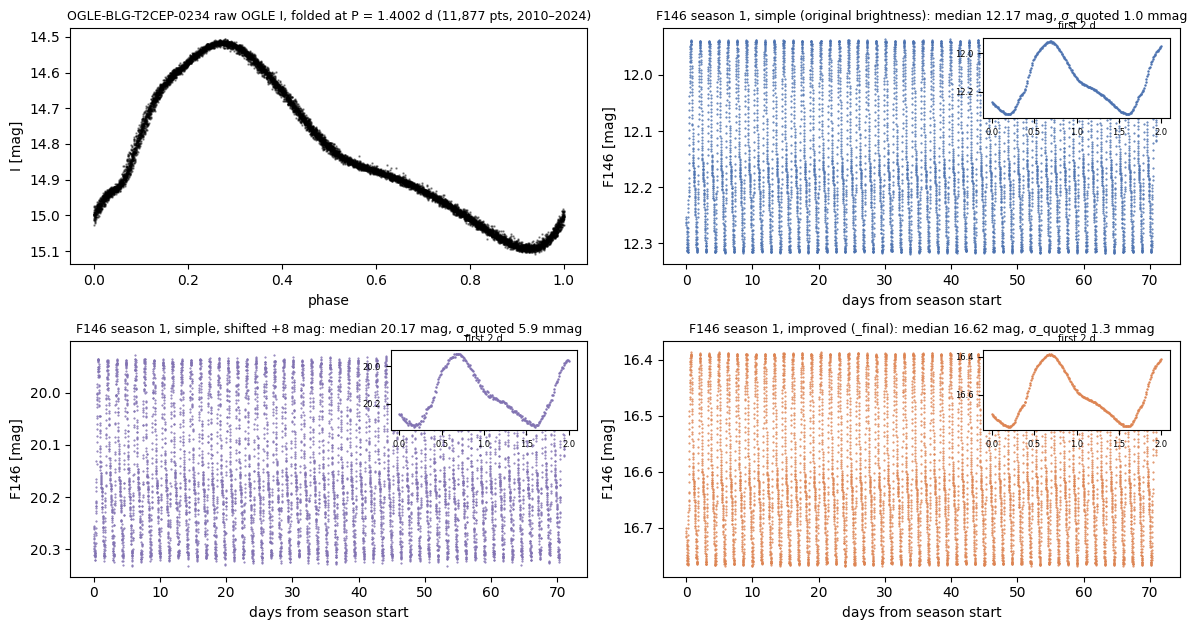

In [12]:
fig_r_same_star();

## Noise model comparison

In [13]:
prof = pd.read_csv(RD/'profile.csv'); f146 = prof[prof.band=='F146']
o = f146[f146.cls!='FL'].copy(); o['mbin'] = o.med_mag.round()
print('median quoted error [mmag] by F146 magnitude:'); print((o.pivot_table(index='mbin', columns='variant', values='med_err', aggfunc='median')*1e3).round(2))
fl = f146[f146.cls=='FL']
print('FL, same objects: median quoted error [mmag] by WFmag'); print((fl.pivot_table(index='wfmag', columns='variant', values='med_err', aggfunc='median')*1e3).round(2))
for v in ['simple','simple_shifted','improved','improved_folder_nonfinal']:
    x = f146[f146.variant==v].dropna(subset=['med_mag','med_err'])
    c = np.polyfit(x.med_mag, np.log10(x.med_err), 3); r = np.log10(x.med_err) - np.polyval(c, x.med_mag)
    print(f'{v:26s} scatter of log10(err) at fixed mag: {np.std(r):.4f} dex (max {np.abs(r).max():.3f})')
nd = pd.read_csv(RD/'noise_diff.csv')
print('whiteness of (variant - simple - offset):'); print(nd.groupby(['variant','cls'])[['std_diff','expected_white','ac1','ac5','bin16','bin64']].median().round(4))
print('offset of each variant from simple:'); print(f146.groupby('variant').off_vs_simple.describe().round(3))

median quoted error [mmag] by F146 magnitude:
variant  improved  simple  simple_shifted
mbin                                     
10.0          NaN    1.00             NaN
11.0          NaN    1.00             NaN
12.0          NaN    1.01             NaN
13.0          NaN    1.02             NaN
14.0         1.00    1.06             NaN
15.0         1.10    1.11             NaN
16.0         1.15    1.31             NaN
17.0         1.27    1.65             NaN
18.0         1.62    2.15            2.33
19.0         2.72     NaN            3.78
20.0         4.27     NaN            5.87
21.0          NaN     NaN            8.46
22.0          NaN     NaN           18.04
23.0          NaN     NaN           27.77
24.0          NaN     NaN           68.74
25.0          NaN     NaN          152.19
26.0          NaN     NaN          307.60
FL, same objects: median quoted error [mmag] by WFmag
variant  improved  improved_folder_nonfinal
wfmag                                      
16.0         1

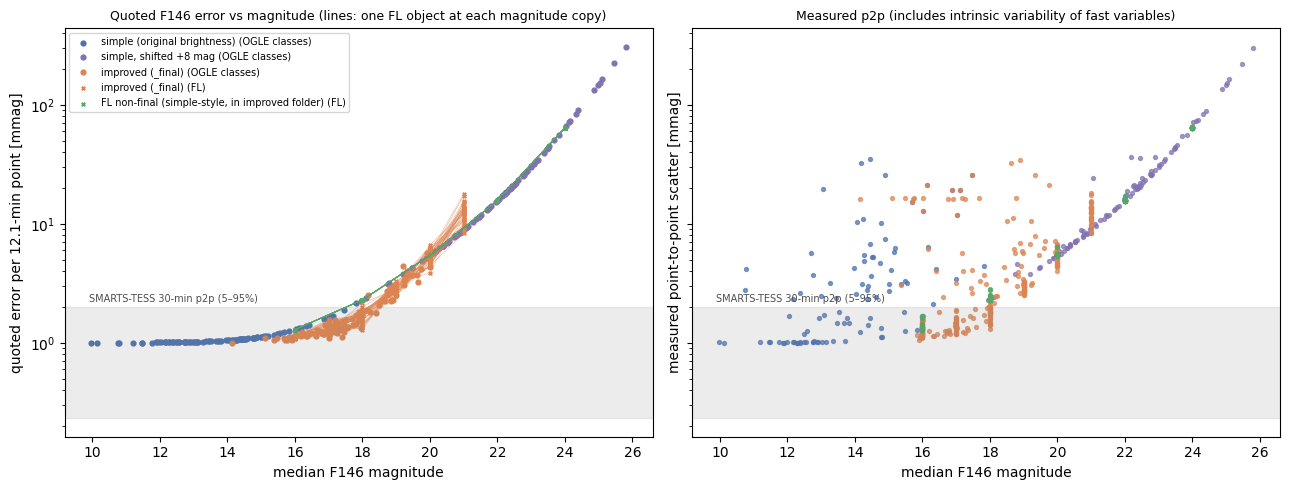

In [14]:
fig_r_noise();

## Cadence / season structure

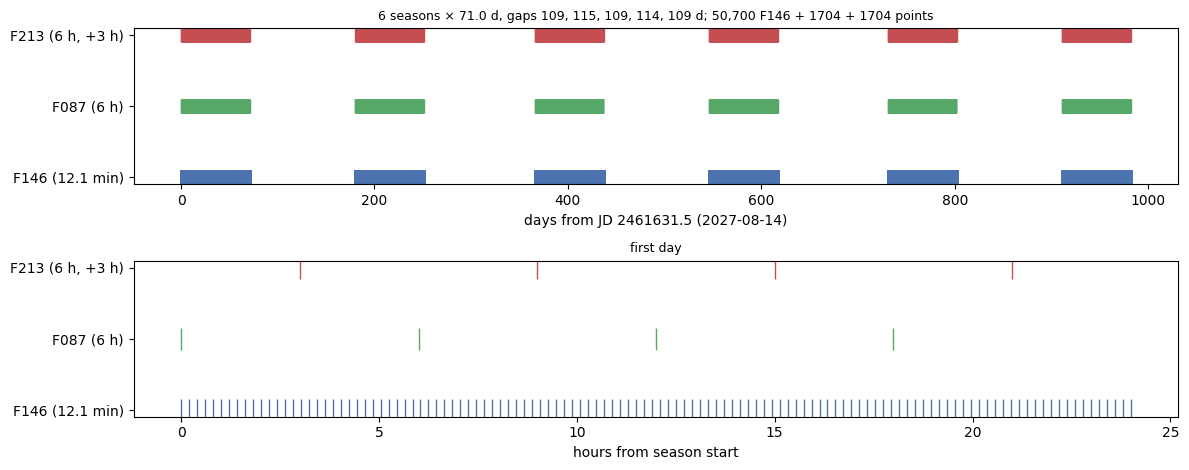

In [15]:
fig_r_coverage();

## Per-class examples (improved noise)

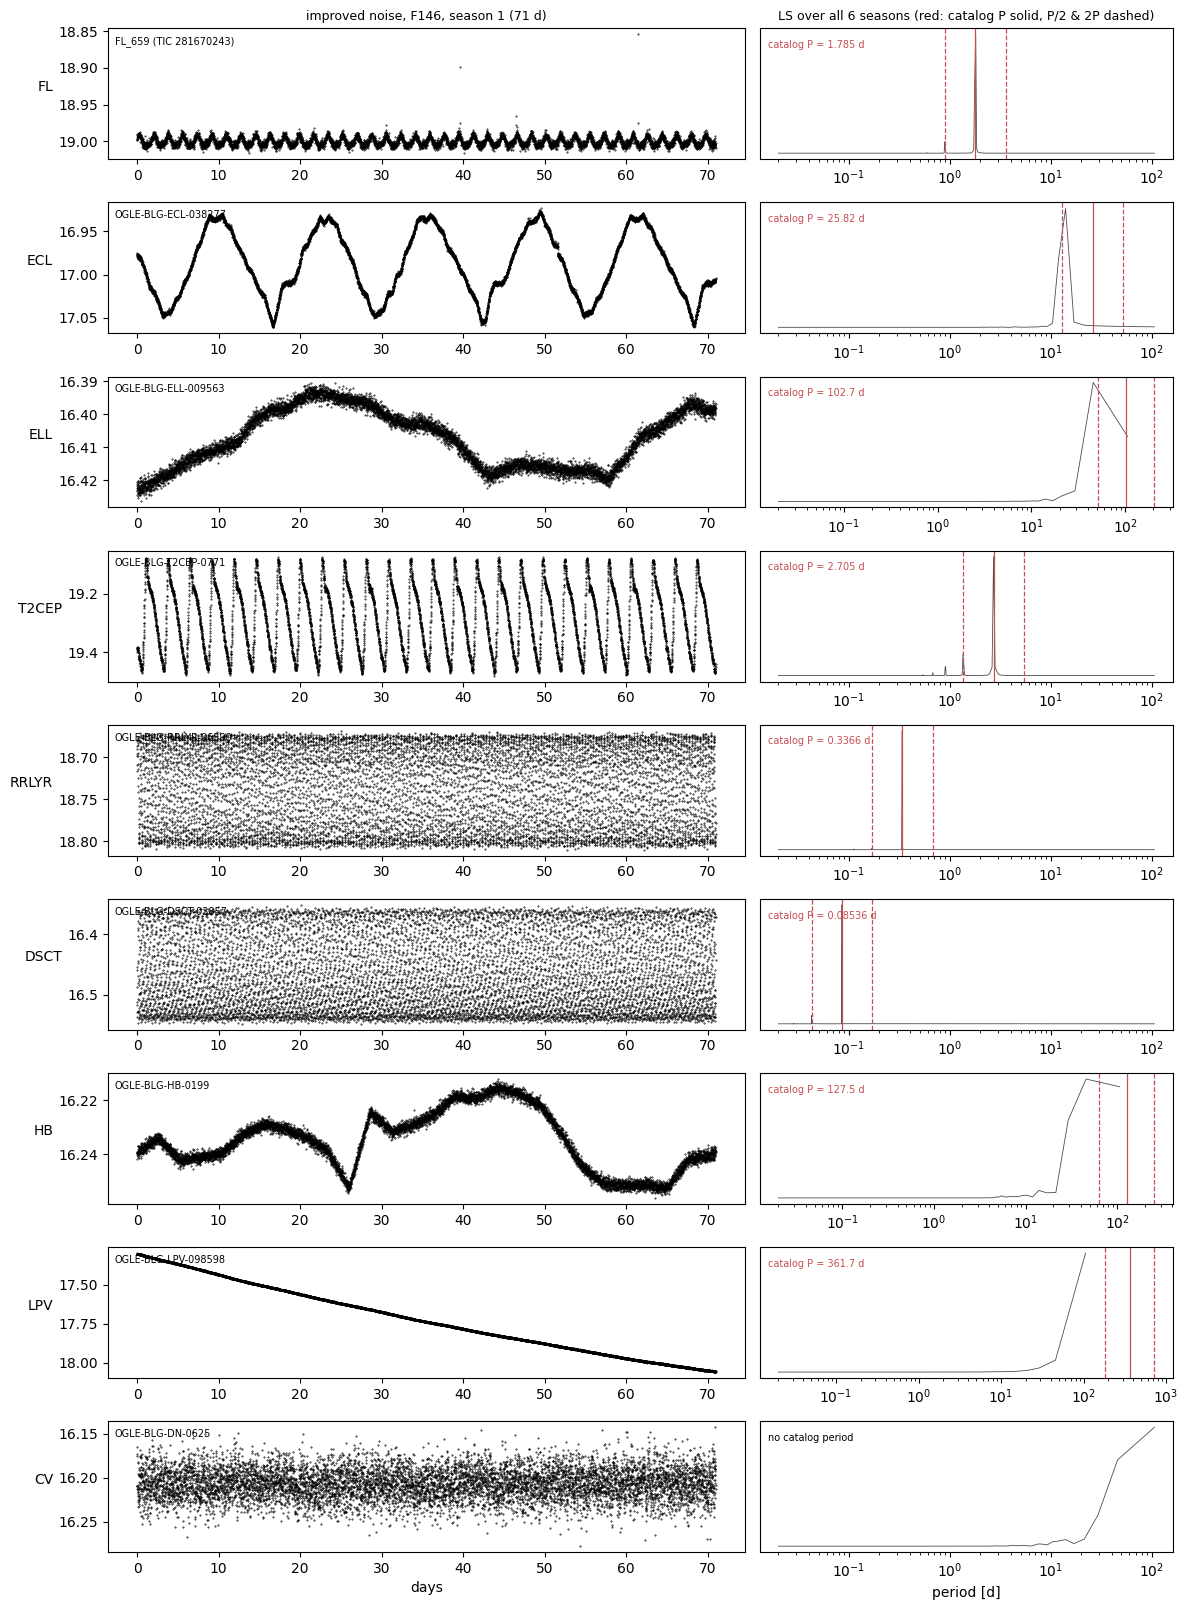

In [16]:
fig_r_examples();

## Stored vs measured periods (LS on F146, all 6 seasons)

outcome                         half  match  na  other  third
variant                  cls                                 
improved                 CV        0      0  12      0      0
                         DSCT      0     12   0      0      0
                         ECL      11      0   0      0      1
                         ELL      12      0   0      0      0
                         FL        0    138  30      6      6
                         HB        9      0   0      1      2
                         LPV       1      5   0      0      6
                         RRLYR     0     12   0      0      0
                         T2CEP     0     12   0      0      0
improved_folder_nonfinal FL        0    114  25      6      5
simple                   CEP       0     12   0      0      0
                         DSCT      0     12   0      0      0
                         ECL      11      0   0      0      1
                         ELL      12      0   0      0      0
        

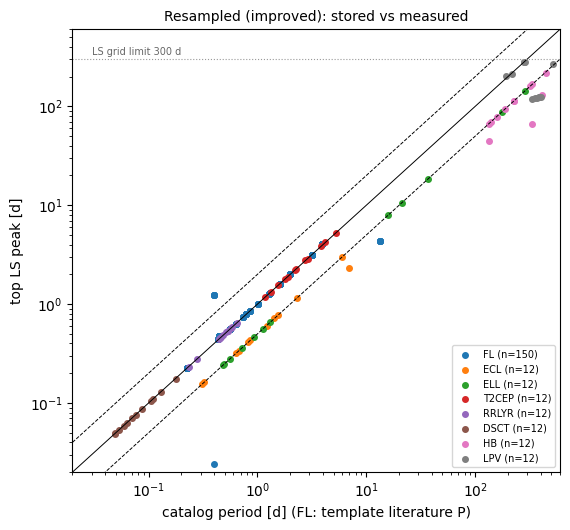

In [17]:
pcr = pd.read_csv(RD/'period_check.csv')
print(pd.crosstab([pcr.variant, pcr.cls], pcr.outcome).to_string())
fig_r_period_check();

## Pipeline on 20 stars (F146 season 1, improved noise, one process)

      cls               star_id     template  med_mag   P_true  P_found  outcome outcome_vs_Porb_half  seconds
0      FL               FL_1869  160329609.0   16.000    1.020    1.012  correct                  NaN    0.899
1      FL               FL_1880  294754396.0   20.999    4.045    7.898   double                  NaN    0.894
2      FL               FL_1482   89257479.0   19.000    1.124    1.123  correct                  NaN    1.718
3      FL               FL_1894  234506911.0   19.997    4.920    4.957  correct                  NaN    0.901
4     ECL   OGLE-BLG-ECL-038296          NaN   19.219    1.212    0.606     half              correct    0.895
5     ECL   OGLE-BLG-ECL-036609          NaN   19.145    1.431    1.431  correct               double    0.933
6     ECL   OGLE-BLG-ECL-036018          NaN   18.442    0.372    0.186     half              correct    0.646
7     ECL   OGLE-BLG-ECL-036316          NaN   19.990    0.451    0.226     half              correct    0.895
8

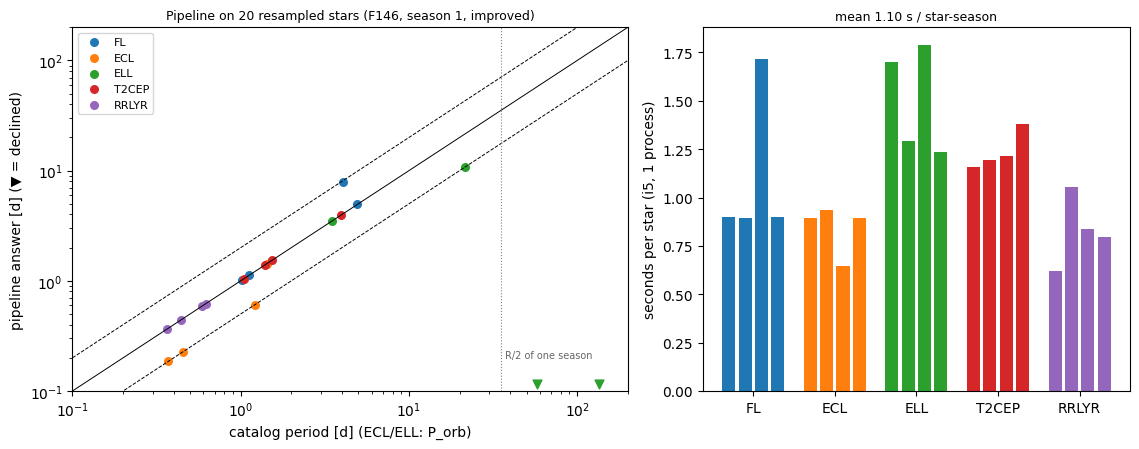

In [18]:
pt = pd.read_csv(RD/'pipeline_test.csv')
print(pt[['cls','star_id','template','med_mag','P_true','P_found','outcome','outcome_vs_Porb_half','seconds']].round(3).to_string())
print(pd.crosstab(pt.cls, pt.outcome)); print(f'mean {pt.seconds.mean():.2f} s, range {pt.seconds.min():.2f}-{pt.seconds.max():.2f} s')
fig_r_pipeline();